Urządzenie: cpu


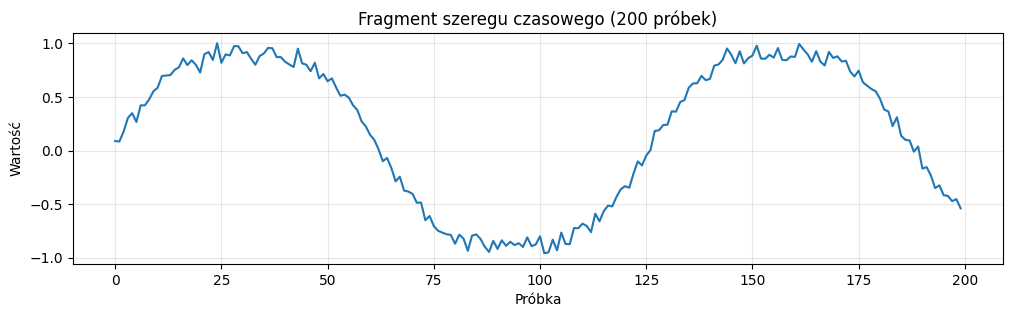


EKSPERYMENT A: PORÓWNANIE TYPU KOMÓRKI
RNN   | Test MSE = 0.003686 | czas = 2.46 s
LSTM  | Test MSE = 0.003438 | czas = 3.84 s
GRU   | Test MSE = 0.003462 | czas = 7.18 s

Tabela porównawcza:


,Typ komórki,Hidden,Okno,Test MSE,Czas [s]
0,RNN,32,30,0.003686,2.464345
1,LSTM,32,30,0.003438,3.835530
2,GRU,32,30,0.003462,7.183773


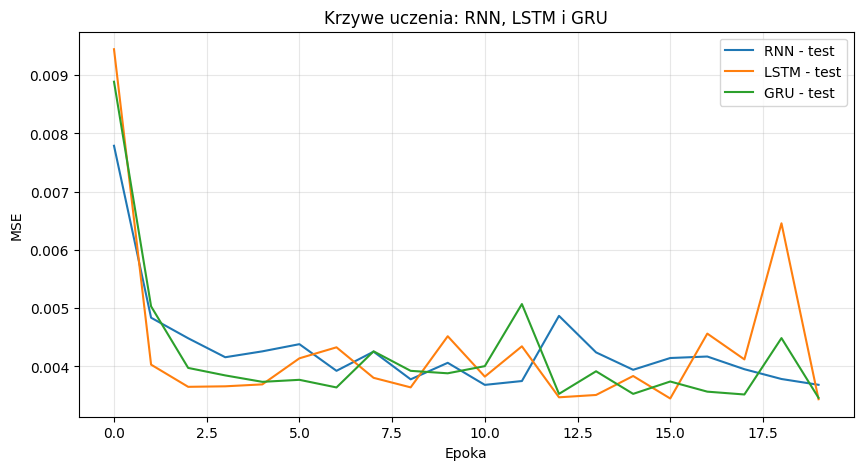


EKSPERYMENT B: LICZBA JEDNOSTEK UKRYTYCH
Hidden= 8 | Test MSE = 0.003736
Hidden=32 | Test MSE = 0.003462
Hidden=64 | Test MSE = 0.004433

Tabela wpływu liczby jednostek:


,Typ komórki,Hidden,Okno,Test MSE
0,GRU,8,30,0.003736
1,GRU,32,30,0.003462
2,GRU,64,30,0.004433


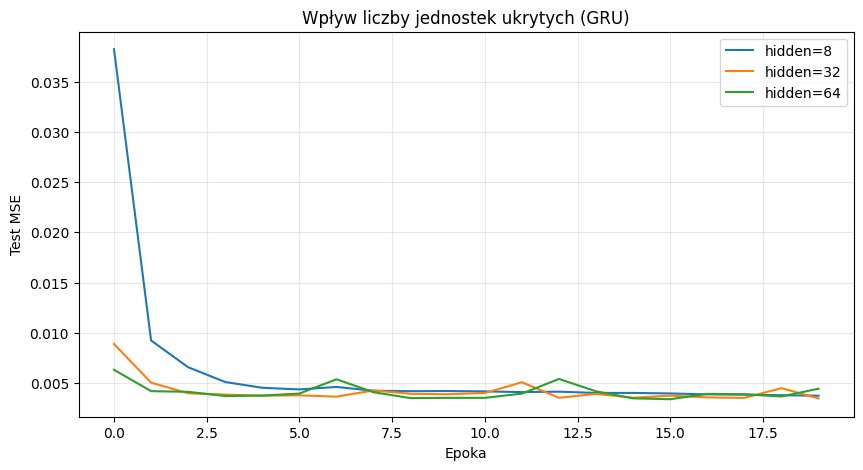


EKSPERYMENT C: DŁUGOŚĆ OKNA WEJŚCIOWEGO
Okno=10 | Test MSE = 0.003970
Okno=30 | Test MSE = 0.003462
Okno=60 | Test MSE = 0.002994

Tabela wpływu długości okna:


,Typ komórki,Hidden,Okno,Test MSE
0,GRU,32,10,0.003970
1,GRU,32,30,0.003462
2,GRU,32,60,0.002994


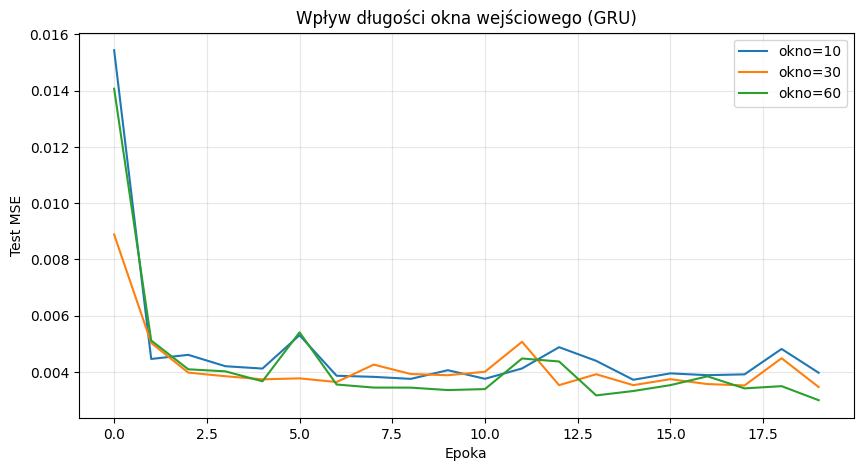

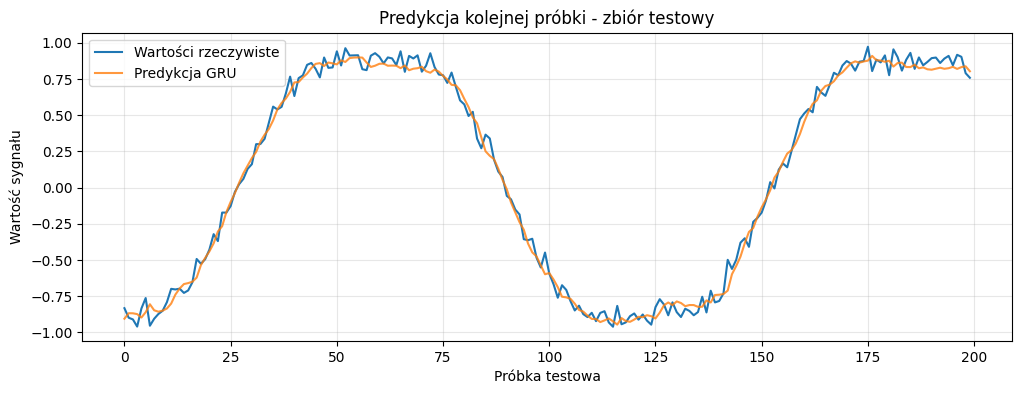


TABELA ZBIORCZA WYNIKÓW


,Typ komórki,Hidden,Okno,Test MSE
0,RNN,32,30,0.003686
1,LSTM,32,30,0.003438
2,GRU,32,30,0.003462
3,GRU,8,30,0.003736
4,GRU,32,30,0.003462
5,GRU,64,30,0.004433
6,GRU,32,10,0.003970
7,GRU,32,30,0.003462
8,GRU,32,60,0.002994


Zapisano tabelę do pliku wyniki_rnn.csv

PODSUMOWANIE:
Najlepszy typ komórki: LSTM, MSE=0.003438
Najlepsza liczba jednostek: 32, MSE=0.003462
Najlepsze okno: 60, MSE=0.002994


In [4]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import random
import time


SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Urządzenie:", DEVICE)

EPOKI = 20
BATCH = 64
LR = 1e-2

#szereg czasowy


def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1 * np.sin(3*t) + 0.05 * np.random.randn(n)
    return y.astype(np.float32)

seria = generuj_szereg()

plt.figure(figsize=(12, 3))
plt.plot(seria[:200])
plt.title("Fragment szeregu czasowego (200 próbek)")
plt.xlabel("Próbka")
plt.ylabel("Wartość")
plt.grid(alpha=0.3)
plt.show()


def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria) - okno):
        X.append(seria[i:i+okno])
        Y.append(seria[i+okno])

    X = np.array(X, dtype=np.float32)[..., None]
    Y = np.array(Y, dtype=np.float32)[:, None]
    return X, Y


def przygotuj_dane(seria, okno):
    X, Y = zrob_okna(seria, okno)


    n_tr = int(0.8 * len(X))

    Xtr = torch.tensor(X[:n_tr], dtype=torch.float32).to(DEVICE)
    Ytr = torch.tensor(Y[:n_tr], dtype=torch.float32).to(DEVICE)
    Xte = torch.tensor(X[n_tr:], dtype=torch.float32).to(DEVICE)
    Yte = torch.tensor(Y[n_tr:], dtype=torch.float32).to(DEVICE)

    return Xtr, Ytr, Xte, Yte



# MODEL RNN / LSTM / GRU


class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()

        warstwy = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        self.rnn = warstwy[typ](
            input_size=1,
            hidden_size=hidden,
            batch_first=True
        )
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


### Funkcja ###



def trenuj(model, Xtr, Ytr, Xte, Yte,
           epoki=20, lr=1e-2, batch=64):

    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    funkcja_straty = nn.MSELoss()

    hist_train = []
    hist_test = []
    n = len(Xtr)

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        suma_strat = 0.0
        liczba = 0

        for i in range(0, n, batch):
            idx = perm[i:i+batch]

            opt.zero_grad()
            pred = model(Xtr[idx])
            loss = funkcja_straty(pred, Ytr[idx])
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=5.0
            )
            opt.step()

            suma_strat += loss.item() * len(idx)
            liczba += len(idx)

        hist_train.append(suma_strat / liczba)

        model.eval()
        with torch.no_grad():
            test_loss = funkcja_straty(
                model(Xte), Yte
            ).item()

        hist_test.append(test_loss)

    return hist_train, hist_test



### RNN VS LSTM VS GRU ###


print("\n" + "="*60)
print("EKSPERYMENT A: PORÓWNANIE TYPU KOMÓRKI")
print("="*60)

Xtr, Ytr, Xte, Yte = przygotuj_dane(seria, okno=30)

wyniki_typ = []
krzywe_typ = {}
modele_typ = {}

for typ in ['RNN', 'LSTM', 'GRU']:

    torch.manual_seed(SEED)

    model = ModelRNN(hidden=32, typ=typ)
    start = time.time()

    train_hist, test_hist = trenuj(
        model, Xtr, Ytr, Xte, Yte,
        epoki=EPOKI, lr=LR, batch=BATCH
    )

    czas = time.time() - start
    modele_typ[typ] = model
    krzywe_typ[typ] = (train_hist, test_hist)

    wyniki_typ.append({
        'Typ komórki': typ,
        'Hidden': 32,
        'Okno': 30,
        'Test MSE': test_hist[-1],
        'Czas [s]': czas
    })

    print(
        f"{typ:5s} | Test MSE = {test_hist[-1]:.6f}"
        f" | czas = {czas:.2f} s"
    )

df_typ = pd.DataFrame(wyniki_typ)
print("\nTabela porównawcza:")
display(df_typ.round(6))

plt.figure(figsize=(10, 5))
for typ, (train_hist, test_hist) in krzywe_typ.items():
    plt.plot(test_hist, label=f'{typ} - test')
plt.title("Krzywe uczenia: RNN, LSTM i GRU")
plt.xlabel("Epoka")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#Liczba jednostek ukrytych (B)


print("\n" + "="*60)
print("EKSPERYMENT B: LICZBA JEDNOSTEK UKRYTYCH")
print("="*60)

wyniki_hidden = []
krzywe_hidden = {}

for hs in [8, 32, 64]:
    torch.manual_seed(SEED)

    model = ModelRNN(hidden=hs, typ='GRU')

    train_hist, test_hist = trenuj(
        model, Xtr, Ytr, Xte, Yte,
        epoki=EPOKI, lr=LR, batch=BATCH
    )

    krzywe_hidden[hs] = (train_hist, test_hist)

    wyniki_hidden.append({
        'Typ komórki': 'GRU',
        'Hidden': hs,
        'Okno': 30,
        'Test MSE': test_hist[-1]
    })

    print(f"Hidden={hs:2d} | Test MSE = {test_hist[-1]:.6f}")

df_hidden = pd.DataFrame(wyniki_hidden)
print("\nTabela wpływu liczby jednostek:")
display(df_hidden.round(6))

plt.figure(figsize=(10, 5))
for hs, (train_hist, test_hist) in krzywe_hidden.items():
    plt.plot(test_hist, label=f'hidden={hs}')
plt.title("Wpływ liczby jednostek ukrytych (GRU)")
plt.xlabel("Epoka")
plt.ylabel("Test MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Długość okna (C)


print("\n" + "="*60)
print("EKSPERYMENT C: DŁUGOŚĆ OKNA WEJŚCIOWEGO")
print("="*60)

wyniki_okno = []
krzywe_okno = {}

for okno in [10, 30, 60]:
    Xtr_o, Ytr_o, Xte_o, Yte_o = przygotuj_dane(
        seria, okno=okno
    )

    torch.manual_seed(SEED)
    model = ModelRNN(hidden=32, typ='GRU')

    train_hist, test_hist = trenuj(
        model, Xtr_o, Ytr_o, Xte_o, Yte_o,
        epoki=EPOKI, lr=LR, batch=BATCH
    )

    krzywe_okno[okno] = (train_hist, test_hist)

    wyniki_okno.append({
        'Typ komórki': 'GRU',
        'Hidden': 32,
        'Okno': okno,
        'Test MSE': test_hist[-1]
    })

    print(f"Okno={okno:2d} | Test MSE = {test_hist[-1]:.6f}")

df_okno = pd.DataFrame(wyniki_okno)
print("\nTabela wpływu długości okna:")
display(df_okno.round(6))

plt.figure(figsize=(10, 5))
for okno, (train_hist, test_hist) in krzywe_okno.items():
    plt.plot(test_hist, label=f'okno={okno}')
plt.title("Wpływ długości okna wejściowego (GRU)")
plt.xlabel("Epoka")
plt.ylabel("Test MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# predykcja


model = modele_typ['GRU']
model.eval()

with torch.no_grad():
    pred = model(Xte).cpu().numpy().ravel()

prawdziwe = Yte.cpu().numpy().ravel()

plt.figure(figsize=(12, 4))
plt.plot(prawdziwe[:200], label='Wartości rzeczywiste')
plt.plot(pred[:200], label='Predykcja GRU', alpha=0.8)
plt.title("Predykcja kolejnej próbki - zbiór testowy")
plt.xlabel("Próbka testowa")
plt.ylabel("Wartość sygnału")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Tabela i eksport wyników ###


wyniki_wszystkie = pd.concat(
    [
        df_typ[['Typ komórki', 'Hidden', 'Okno', 'Test MSE']],
        df_hidden[['Typ komórki', 'Hidden', 'Okno', 'Test MSE']],
        df_okno[['Typ komórki', 'Hidden', 'Okno', 'Test MSE']]
    ],
    ignore_index=True
)

print("\n" + "="*60)
print("TABELA ZBIORCZA WYNIKÓW")
print("="*60)
display(wyniki_wszystkie.round(6))

wyniki_wszystkie.to_csv(
    'wyniki_rnn.csv', index=False, sep=';', decimal=','
)
print("Zapisano tabelę do pliku wyniki_rnn.csv")



#### PODSUMOWANIE ####


najlepszy_typ = df_typ.loc[df_typ['Test MSE'].idxmin()]
najlepszy_hidden = df_hidden.loc[df_hidden['Test MSE'].idxmin()]
najlepsze_okno = df_okno.loc[df_okno['Test MSE'].idxmin()]

print("\nPODSUMOWANIE:")
print(
    f"Najlepszy typ komórki: {najlepszy_typ['Typ komórki']}, "
    f"MSE={najlepszy_typ['Test MSE']:.6f}"
)
print(
    f"Najlepsza liczba jednostek: {int(najlepszy_hidden['Hidden'])}, "
    f"MSE={najlepszy_hidden['Test MSE']:.6f}"
)
print(
    f"Najlepsze okno: {int(najlepsze_okno['Okno'])}, "
    f"MSE={najlepsze_okno['Test MSE']:.6f}"
)
